# Modelo — prever readmissão em < 30 dias

**Objetivo:** dar a cada internação um **escore de risco** de readmissão em < 30 dias,
para priorizar quem recebe intervenção na alta (educação em saúde, retorno precoce,
contato telefônico).

**Decisões de método (e por quê):**

| Decisão | Motivo |
|---|---|
| Treino/teste separados **por paciente** | O mesmo paciente aparece em várias internações. Se ele estiver nos dois lados, o modelo "decora" o paciente e a métrica fica otimista. |
| Métricas **ROC-AUC** e **PR-AUC**, não acurácia | Só 11% são readmitidos: prever "ninguém volta" já dá 89% de acurácia. |
| `class_weight="balanced"` | Faz o modelo dar mais peso aos poucos casos positivos. |
| Base de comparação + 2 modelos | Regressão logística (interpretável) e gradient boosting (captura não linearidades). |

In [1]:
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix, precision_recall_curve,
                             roc_auc_score, roc_curve)
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIGURAS = RAIZ / "reports" / "figures"
MODELOS = RAIZ / "models"
MODELOS.mkdir(exist_ok=True)
SEMENTE = 42

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"
TINTA, TINTA_2, SUPERFICIE = "#0b0b0b", "#52514e", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
    "axes.edgecolor": "#d6d5d0", "axes.labelcolor": TINTA_2,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "text.color": TINTA,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "axes.axisbelow": True, "font.size": 11, "figure.dpi": 110,
})

df = pd.read_csv(RAIZ / "data-processed" / "dataset_modelo.csv")
y = df["readmit_30"]
grupos = df["patient_nbr"]
X = df.drop(columns=["readmit_30", "patient_nbr"])

numericas = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
categoricas = [c for c in X.columns if c not in numericas]
print(f"{X.shape[0]:,} internacoes | {len(numericas)} numericas | {len(categoricas)} categoricas")

99,340 internacoes | 16 numericas | 23 categoricas


## 1. Separação treino / teste por paciente (80 / 20)

In [2]:
divisor = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMENTE)
idx_treino, idx_teste = next(divisor.split(X, y, groups=grupos))
X_treino, X_teste = X.iloc[idx_treino], X.iloc[idx_teste]
y_treino, y_teste = y.iloc[idx_treino], y.iloc[idx_teste]
g_treino = grupos.iloc[idx_treino]

assert set(grupos.iloc[idx_treino]).isdisjoint(grupos.iloc[idx_teste]), "Paciente nos dois lados!"
pd.DataFrame({
    "internacoes": [len(y_treino), len(y_teste)],
    "taxa_readmissao": [y_treino.mean(), y_teste.mean()],
}, index=["treino", "teste"]).style.format({"internacoes": "{:,}", "taxa_readmissao": "{:.1%}"})

,internacoes,taxa_readmissao
treino,"79,567",11.4%
teste,"19,773",11.3%


## 2. Modelos

- **Base (Dummy):** sorteia respeitando a proporção de classes. Qualquer modelo útil precisa superá-lo.
- **Regressão logística:** variáveis numéricas padronizadas + categóricas em *one-hot*.
- **Gradient boosting (HistGradientBoosting):** árvores em sequência; categóricas tratadas nativamente.

In [3]:
prep_linear = ColumnTransformer([
    ("num", StandardScaler(), numericas),
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50), categoricas),
])
prep_arvore = ColumnTransformer([
    ("num", "passthrough", numericas),
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), categoricas),
])
mascara_cat = [False] * len(numericas) + [True] * len(categoricas)

modelos = {
    "Base (Dummy)": DummyClassifier(strategy="stratified", random_state=SEMENTE),
    "Regressao logistica": Pipeline([
        ("prep", prep_linear),
        ("modelo", LogisticRegression(class_weight="balanced", max_iter=2000, C=0.1)),
    ]),
    "Gradient boosting": Pipeline([
        ("prep", prep_arvore),
        ("modelo", HistGradientBoostingClassifier(
            categorical_features=mascara_cat, class_weight="balanced",
            learning_rate=0.05, max_iter=300, max_leaf_nodes=31, l2_regularization=1.0,
            early_stopping=True, random_state=SEMENTE)),
    ]),
}

### 2.1 Validação cruzada no treino (5 folds, agrupados por paciente)

Mostra a média e a variação entre folds — um resultado estável é mais confiável.

In [4]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMENTE)
linhas = []
for nome, modelo in modelos.items():
    r = cross_validate(modelo, X_treino, y_treino, groups=g_treino, cv=cv,
                       scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision"}, n_jobs=-1)
    linhas.append({"modelo": nome,
                   "ROC-AUC": f"{r['test_roc_auc'].mean():.3f} ± {r['test_roc_auc'].std():.3f}",
                   "PR-AUC": f"{r['test_pr_auc'].mean():.3f} ± {r['test_pr_auc'].std():.3f}"})
pd.DataFrame(linhas).set_index("modelo")

,ROC-AUC,PR-AUC
modelo,,
Base (Dummy),0.498 ± 0.001,0.114 ± 0.000
Regressao logistica,0.663 ± 0.004,0.211 ± 0.008
Gradient boosting,0.676 ± 0.002,0.225 ± 0.007


## 3. Avaliação final no conjunto de teste

In [5]:
probas = {}
for nome, modelo in modelos.items():
    modelo.fit(X_treino, y_treino)
    probas[nome] = modelo.predict_proba(X_teste)[:, 1]

resultado_teste = pd.DataFrame({
    nome: {"ROC-AUC": roc_auc_score(y_teste, p), "PR-AUC": average_precision_score(y_teste, p)}
    for nome, p in probas.items()
}).T
resultado_teste.style.format("{:.3f}")

,ROC-AUC,PR-AUC
Base (Dummy),0.498,0.113
Regressao logistica,0.675,0.224
Gradient boosting,0.686,0.243


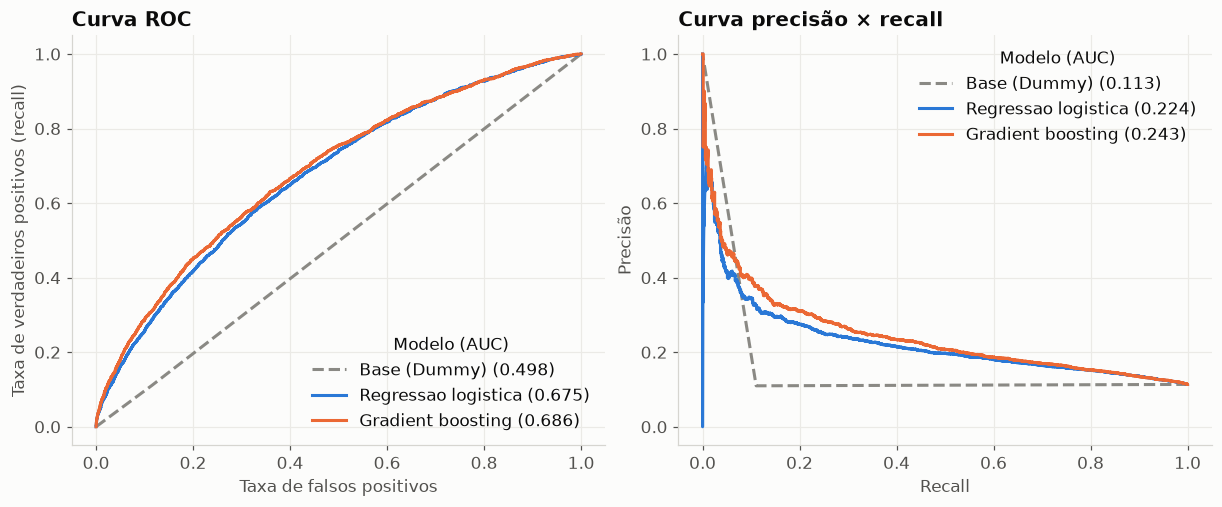

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
cores = {"Base (Dummy)": CINZA, "Regressao logistica": AZUL, "Gradient boosting": LARANJA}
for nome, p in probas.items():
    fpr, tpr, _ = roc_curve(y_teste, p)
    prec, rec, _ = precision_recall_curve(y_teste, p)
    estilo = "--" if nome.startswith("Base") else "-"
    ax1.plot(fpr, tpr, estilo, color=cores[nome], lw=2,
             label=f"{nome} ({roc_auc_score(y_teste, p):.3f})")
    ax2.plot(rec, prec, estilo, color=cores[nome], lw=2,
             label=f"{nome} ({average_precision_score(y_teste, p):.3f})")
ax1.set(xlabel="Taxa de falsos positivos", ylabel="Taxa de verdadeiros positivos (recall)")
ax1.set_title("Curva ROC", loc="left", fontweight="bold")
ax2.set(xlabel="Recall", ylabel="Precisão")
ax2.set_title("Curva precisão × recall", loc="left", fontweight="bold")
ax1.legend(title="Modelo (AUC)", frameon=False, loc="lower right")
ax2.legend(title="Modelo (AUC)", frameon=False, loc="upper right")
fig.savefig(FIGURAS / "10_curvas_roc_pr.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. O modelo na prática: estratificação de risco

Uma AUC isolada é abstrata. A pergunta útil para a equipe é:
**se eu priorizar os pacientes de maior risco, quantas readmissões eu alcanço?**

Ordenamos as internações do teste pelo risco previsto e dividimos em 10 faixas (decis).

Modelo escolhido: Gradient boosting


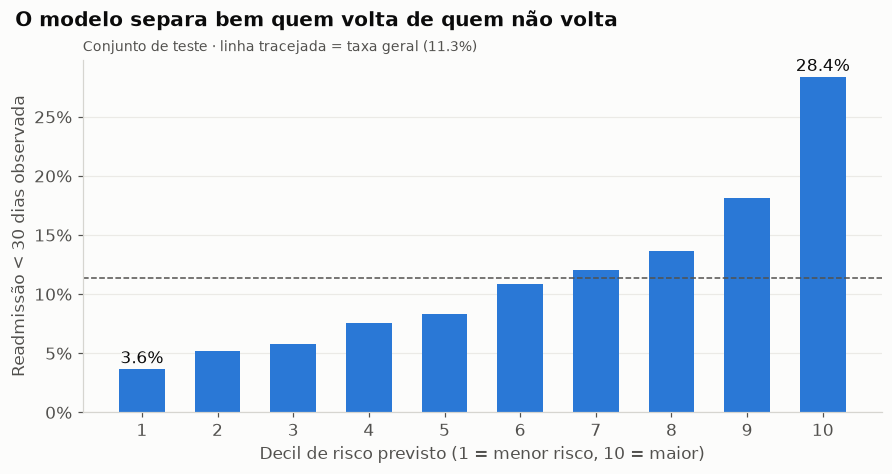

,readmissoes alcancadas,taxa no grupo
pacientes priorizados,,
10% de maior risco,25.0%,28.4%
20% de maior risco,41.0%,23.2%
30% de maior risco,53.0%,20.0%


In [7]:
melhor = resultado_teste.drop("Base (Dummy)")["ROC-AUC"].idxmax()
print(f"Modelo escolhido: {melhor}")
risco = pd.DataFrame({"y": y_teste.values, "p": probas[melhor]})
risco["decil"] = pd.qcut(risco["p"].rank(method="first"), 10, labels=range(1, 11))
decis = risco.groupby("decil", observed=True)["y"].agg(internacoes="size", readmissoes="sum", taxa="mean")

fig, ax = plt.subplots(figsize=(8, 4.2), layout="constrained")
ax.bar(decis.index.astype(int), decis["taxa"], width=0.6, color=AZUL)
ax.axhline(y_teste.mean(), color=TINTA_2, ls="--", lw=1)
for d in (1, 10):
    v = decis.loc[d, "taxa"]
    ax.annotate(f"{v:.1%}", (d, v), xytext=(0, 4), textcoords="offset points", ha="center")
ax.set_xticks(range(1, 11))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.grid(axis="x", visible=False)
ax.set(xlabel="Decil de risco previsto (1 = menor risco, 10 = maior)", ylabel="Readmissão < 30 dias observada")
fig.suptitle("O modelo separa bem quem volta de quem não volta", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
ax.set_title(f"Conjunto de teste · linha tracejada = taxa geral ({y_teste.mean():.1%})",
             loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "11_decis_de_risco.png", dpi=150, bbox_inches="tight")
plt.show()

decis_cum = decis.iloc[::-1].cumsum()
alcance = pd.DataFrame({
    "pacientes priorizados": [f"{k}0% de maior risco" for k in (1, 2, 3)],
    "readmissoes alcancadas": [decis_cum["readmissoes"].iloc[k - 1] / decis["readmissoes"].sum() for k in (1, 2, 3)],
    "taxa no grupo": [decis_cum["readmissoes"].iloc[k - 1] / decis_cum["internacoes"].iloc[k - 1] for k in (1, 2, 3)],
}).set_index("pacientes priorizados")
alcance.style.format("{:.1%}")

### 4.1 Escolha de um ponto de corte

O modelo dá uma probabilidade; a equipe precisa de "alto risco: sim/não".
Escolhemos o corte que marca os **20% de maior risco** como alto risco — um volume
plausível para uma intervenção de enfermagem na alta.

In [8]:
corte = np.quantile(probas[melhor], 0.80)
pred = (probas[melhor] >= corte).astype(int)
vn, fp, fn, vp = confusion_matrix(y_teste, pred).ravel()
pd.Series({
    "Ponto de corte (probabilidade)": f"{corte:.3f}",
    "Recall (readmissoes identificadas)": f"{vp / (vp + fn):.1%}",
    "Precisao (alto risco que de fato voltou)": f"{vp / (vp + fp):.1%}",
    "Verdadeiros positivos": f"{vp:,}",
    "Falsos positivos": f"{fp:,}",
    "Falsos negativos": f"{fn:,}",
    "Verdadeiros negativos": f"{vn:,}",
}).to_frame("valor")

,valor
Ponto de corte (probabilidade),0.584
Recall (readmissoes identificadas),41.0%
Precisao (alto risco que de fato voltou),23.2%
Verdadeiros positivos,919
Falsos positivos,"3,036"
Falsos negativos,"1,325"
Verdadeiros negativos,"14,493"


## 5. O que o modelo aprendeu

### 5.1 Regressão logística — razões de chance (odds ratios)

OR > 1 aumenta o risco; OR < 1 reduz. Variáveis numéricas estão padronizadas
(efeito de +1 desvio-padrão).

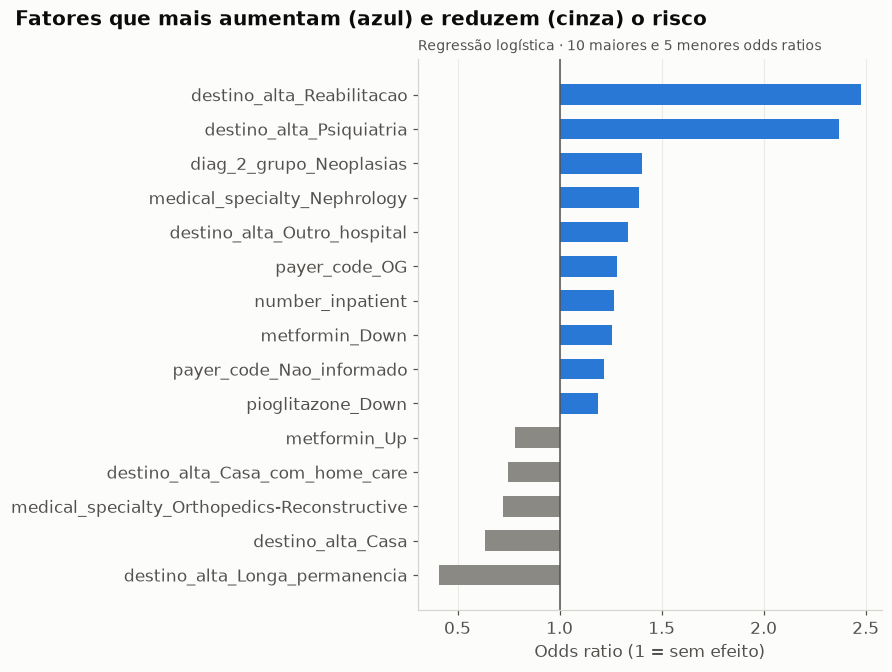

In [9]:
rl = modelos["Regressao logistica"]
nomes = rl.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(rl.named_steps["modelo"].coef_[0], index=nomes)
odds = np.exp(coefs).rename("odds_ratio")
odds.index = odds.index.str.replace("num__", "").str.replace("cat__", "")
top = pd.concat([odds.nlargest(10), odds.nsmallest(5)]).sort_values()

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
cores_barra = [AZUL if v >= 1 else CINZA for v in top]
ax.barh(top.index, top - 1, left=1, color=cores_barra, height=0.6)
ax.axvline(1, color=TINTA_2, lw=1)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Odds ratio (1 = sem efeito)")
fig.suptitle("Fatores que mais aumentam (azul) e reduzem (cinza) o risco", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
ax.set_title("Regressão logística · 10 maiores e 5 menores odds ratios", loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "12_odds_ratios.png", dpi=150, bbox_inches="tight")
plt.show()

### 5.2 Importância por permutação (modelo escolhido)

Quanto a ROC-AUC do teste cai quando embaralhamos cada variável. Quanto maior a queda,
mais o modelo depende dela.

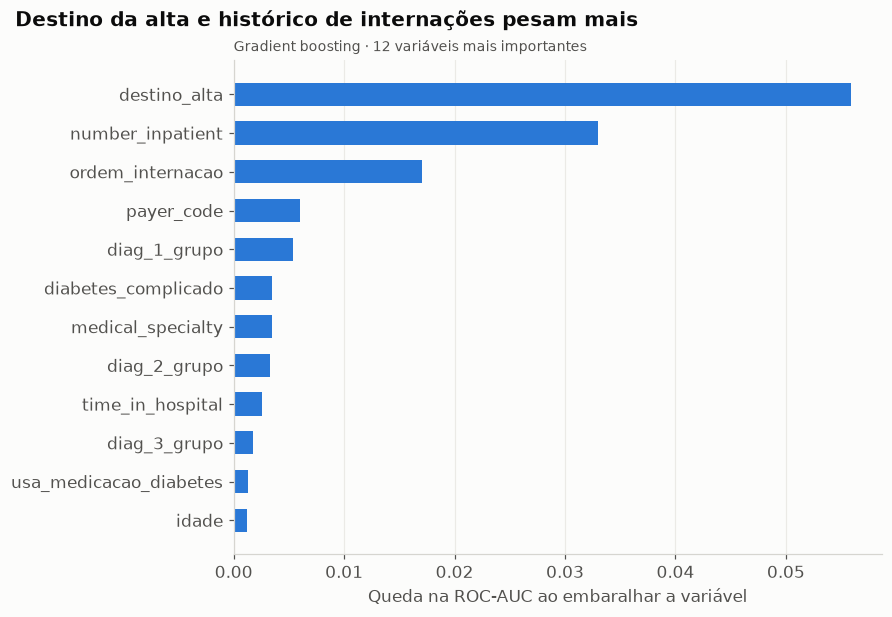

In [10]:
amostra = X_teste.sample(8000, random_state=SEMENTE)
imp = permutation_importance(modelos[melhor], amostra, y_teste.loc[amostra.index],
                             scoring="roc_auc", n_repeats=5, random_state=SEMENTE, n_jobs=-1)
importancia = pd.Series(imp.importances_mean, index=amostra.columns).nlargest(12).sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5), layout="constrained")
ax.barh(importancia.index, importancia, color=AZUL, height=0.6)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Queda na ROC-AUC ao embaralhar a variável")
fig.suptitle("Destino da alta e histórico de internações pesam mais", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
ax.set_title(f"{melhor} · 12 variáveis mais importantes", loc="left", fontsize=9, color=TINTA_2)
fig.savefig(FIGURAS / "13_importancia_variaveis.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Salvar o modelo final (usado pelo dashboard)

In [11]:
artefato = {
    "modelo": modelos[melhor],
    "nome": melhor,
    "corte_alto_risco": float(corte),
    "colunas": X.columns.tolist(),
    "metricas_teste": resultado_teste.loc[melhor].to_dict(),
    "taxa_base": float(y.mean()),
}
joblib.dump(artefato, MODELOS / "modelo_readmissao.joblib", compress=3)
print(f"Salvo: models/modelo_readmissao.joblib ({melhor})")

Salvo: models/modelo_readmissao.joblib (Gradient boosting)


## 7. Conclusões e limitações

**Resultados (conjunto de teste, pacientes nunca vistos no treino):**
- **Gradient boosting: ROC-AUC 0,686 e PR-AUC 0,243** (regressão logística: 0,675 / 0,224;
  base aleatória: 0,50 / 0,11). Os folds da validação cruzada variam pouco (± 0,002), então o
  resultado é estável. A AUC moderada é típica deste dataset na literatura: readmissão depende
  de muita coisa que não está nos dados (suporte social, adesão, acesso a consulta pós-alta).
- O valor prático está na **estratificação**: o decil de maior risco volta **28,4%** das vezes,
  contra **3,6%** no de menor risco — quase 8 vezes mais. Priorizar os **20% de maior risco
  alcança 41% de todas as readmissões** (o dobro de escolher pacientes ao acaso).
- O que mais pesa é o **destino da alta** e o **histórico de internações** (internações no ano
  anterior e internações repetidas no próprio dataset), seguidos do diagnóstico e de diabetes
  com complicação — coerente com a análise exploratória.

**Limitações:**
- Dados de 1999–2008, de hospitais dos EUA: o perfil de cuidado mudou e o modelo precisaria ser
  revalidado em dados locais e atuais antes de qualquer uso real.
- Não há variáveis sociais nem de cuidado pós-alta.
- O modelo aponta **associação, não causa**: "não medir HbA1c" não causa readmissão, mas pode
  indicar um cuidado menos atento ao diabetes.

> ✍️ **Para a autora:** como uma equipe de enfermagem usaria esse escore na prática?
> (ex.: checklist de alta reforçado, ligação em 48 h, consulta de retorno em 7 dias para os de alto risco.)